<a href="https://colab.research.google.com/github/ayuannisa17/PCdVK_ganjil_2026/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum PCVK Modul 9: Morfologi



## 1. Membuka Google Colab dan menghubungkan Google Drive

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Import library

In [13]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

# Lokasi gambar
IMAGE_DIR = Path('/content/drive/MyDrive/PCdVK/Images')

PLATE_PATH = str(IMAGE_DIR / 'plat nomer.png')
KITTEN_PATH = str(IMAGE_DIR / 'kitten01.png')
LILY_PATH = str(IMAGE_DIR / 'lily.png')

# Cek gambar
for path in [PLATE_PATH, KITTEN_PATH, LILY_PATH]:
    print(path, Path(path).exists())


/content/drive/MyDrive/PCdVK/Images/plat nomer.png False
/content/drive/MyDrive/PCdVK/Images/kitten01.png False
/content/drive/MyDrive/PCdVK/Images/lily.png False


## 3. Dilasi tanpa library morphology OpenCV – SED Cross 3×3


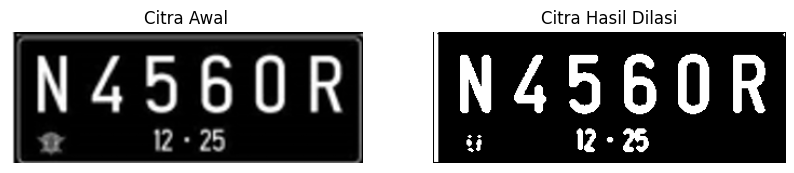

In [16]:
# NOMOR 3 - DILASI TANPA LIBRARY

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Lokasi gambar
IMAGE_DIR = '/content/drive/MyDrive/PCdVK'

PLATE_PATH = IMAGE_DIR + '/plat nomor.png'
KITTEN_PATH = IMAGE_DIR + '/kitten1.png'
LILY_PATH = IMAGE_DIR + '/lily.png'

# Membaca gambar
img_d = cv2.imread(PLATE_PATH, 0)

# Threshold
ret, thresh = cv2.threshold(
    img_d, 125, 200, cv2.THRESH_BINARY
)

# Fungsi dilasi
def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    SED = np.array([
        [0, 1, 0],
        [1, 1, 1],
        [0, 1, 0]
    ], dtype=np.uint8)

    constant = (w - 1) // 2

    for i in range(constant, p - constant):
        for j in range(constant, q - constant):
            temp = F[
                i-constant:i+constant+1,
                j-constant:j+constant+1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

# Proses dilasi
w = 3
imgD = dilasi_citra(thresh, w)

# Menampilkan hasil
plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi')
plt.axis('off')

plt.show()

## 4. Dilasi menggunakan library morphology OpenCV – SED Cross 3×3

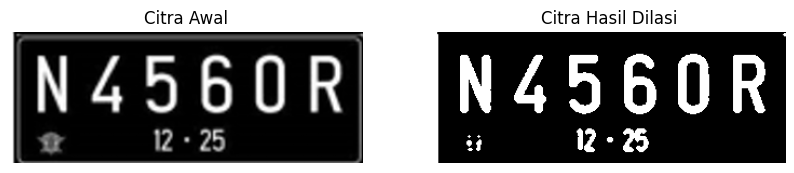

In [17]:
img = cv2.imread(PLATE_PATH, 0)

ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

kernel = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

dilasi = cv2.dilate(thresh, kernel, iterations=1)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(dilasi, cmap='gray')
plt.title('Citra Hasil Dilasi')
plt.axis('off')
plt.show()

## 5. Erosi tanpa library morphology OpenCV – SE Square 5×5

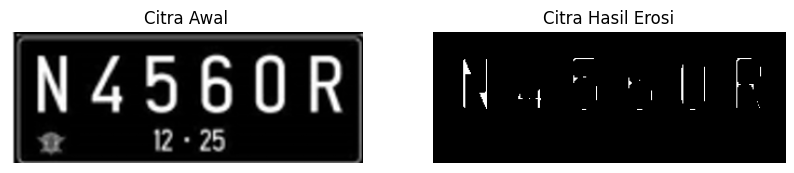

In [18]:
def erosi_citra(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i-constant:i+constant+1,
                     j-constant:j+constant+1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


img_e = cv2.imread(PLATE_PATH, 0)
ret, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)

k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi')
plt.axis('off')
plt.show()

## 6. Erosi menggunakan library morphology OpenCV – SE Square 5×5

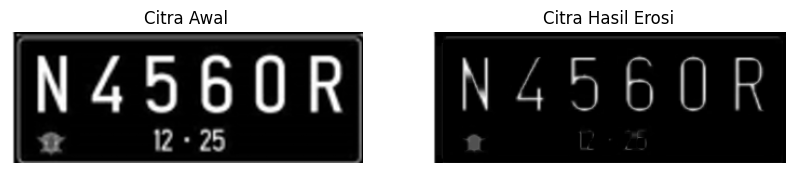

In [19]:
img = cv2.imread(PLATE_PATH, 0)

kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(erosion, cmap='gray')
plt.title('Citra Hasil Erosi')
plt.axis('off')
plt.show()

## 7. Opening  SE Square 3×3, tanpa dan dengan library morphology


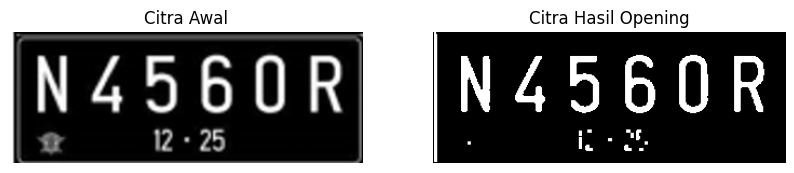

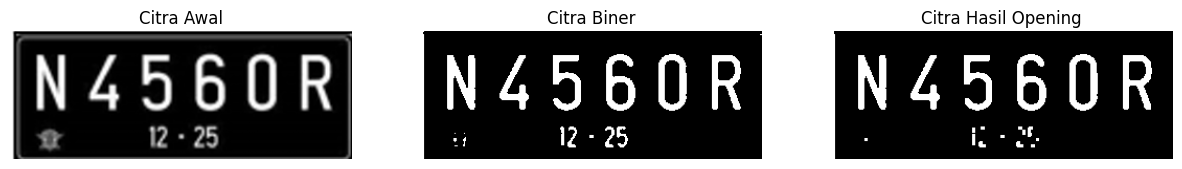

In [20]:
# Opening tanpa library
def dilasi_square(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgD = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m-constant):
        for j in range(constant, n-constant):
            temp = F[i-constant:i+constant+1,
                     j-constant:j+constant+1]
            imgD[i, j] = np.max(temp * SE)

    return imgD


img_o = cv2.imread(PLATE_PATH, 0)
ret, thresh_o = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)

k = 3
imgO = dilasi_square(erosi_citra(thresh_o, k), k)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening')
plt.axis('off')
plt.show()


# Opening dengan library
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh_o, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131)
plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(132)
plt.imshow(thresh_o, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(133)
plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening')
plt.axis('off')
plt.show()

## 8. Closing – SE Square 3×3, tanpa dan dengan library morphology


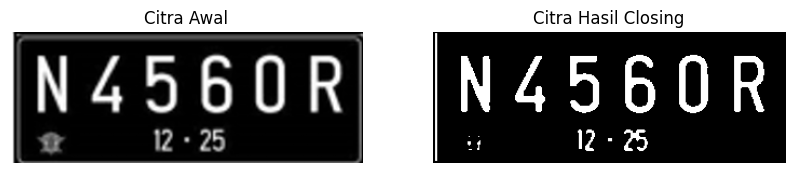

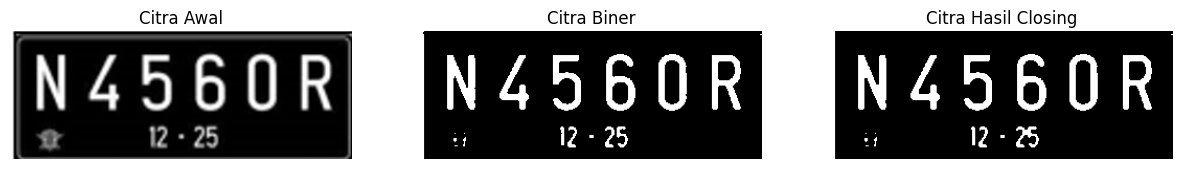

In [21]:
# Closing tanpa library
img_c = cv2.imread(PLATE_PATH, 0)
ret, thresh_c = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)

k = 3
imgC = erosi_citra(dilasi_square(thresh_c, k), k)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing')
plt.axis('off')
plt.show()


# Closing dengan library
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh_c, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(15, 5))
plt.subplot(131)
plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(132)
plt.imshow(thresh_c, cmap='gray')
plt.title('Citra Biner')
plt.axis('off')

plt.subplot(133)
plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing')
plt.axis('off')
plt.show()

## 9. Dilasi dengan Structuring Element Cross 3×3 dan 5×5

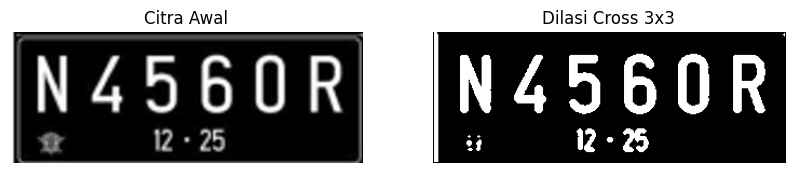

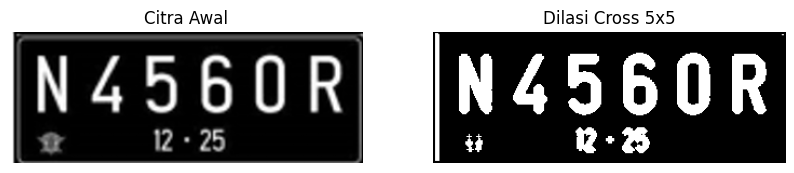

In [22]:
def dilasi_cross(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    if w == 3:
        SED = np.array([
            [0, 1, 0],
            [1, 1, 1],
            [0, 1, 0]
        ], dtype=np.uint8)

    else:
        SED = np.array([
            [0, 0, 1, 0, 0],
            [0, 0, 1, 0, 0],
            [1, 1, 1, 1, 1],
            [0, 0, 1, 0, 0],
            [0, 0, 1, 0, 0]
        ], dtype=np.uint8)

    constant = (w - 1) // 2

    for i in range(constant, p-constant):
        for j in range(constant, q-constant):
            temp = F[i-constant:i+constant+1,
                     j-constant:j+constant+1]
            imgD[i, j] = np.max(temp * SED)

    return imgD


img_d = cv2.imread(PLATE_PATH, 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

for w in [3, 5]:
    imgD = dilasi_cross(thresh, w)

    plt.figure(figsize=(10, 5))
    plt.subplot(121)
    plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal')
    plt.axis('off')

    plt.subplot(122)
    plt.imshow(imgD, cmap='gray')
    plt.title(f'Dilasi Cross {w}x{w}')
    plt.axis('off')
    plt.show()

## 10. Dilasi dengan Structuring Element Circular 3×3 dan 5×5

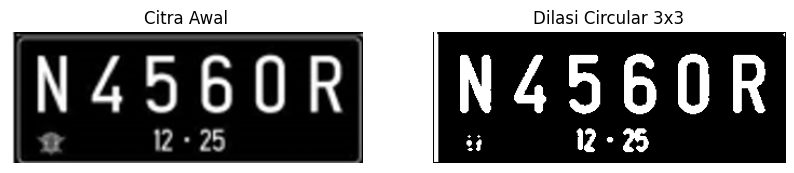

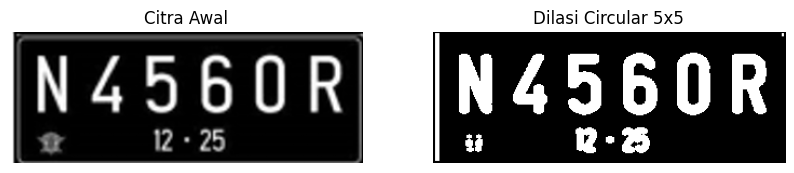

In [23]:
def dilasi_circular(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    SED = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (w, w)
    )

    constant = (w - 1) // 2

    for i in range(constant, p-constant):
        for j in range(constant, q-constant):
            temp = F[i-constant:i+constant+1,
                     j-constant:j+constant+1]
            imgD[i, j] = np.max(temp * SED)

    return imgD


img_d = cv2.imread(PLATE_PATH, 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

for w in [3, 5]:
    imgD = dilasi_circular(thresh, w)

    plt.figure(figsize=(10, 5))
    plt.subplot(121)
    plt.imshow(img_d, cmap='gray')
    plt.title('Citra Awal')
    plt.axis('off')

    plt.subplot(122)
    plt.imshow(imgD, cmap='gray')
    plt.title(f'Dilasi Circular {w}x{w}')
    plt.axis('off')
    plt.show()

## 11. Erosi dengan Structuring Element Rectangle 3×5 dan 5×7

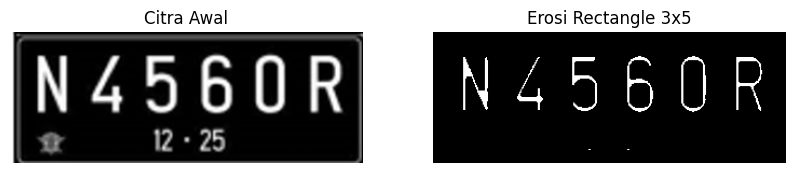

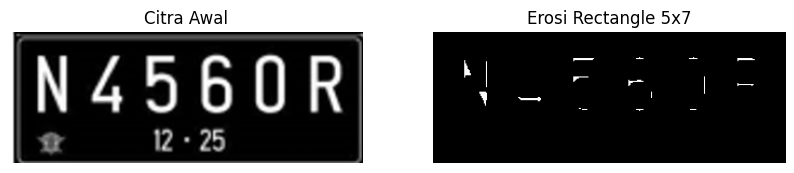

In [24]:
def erosi_rectangle(F, p, l):
    m, n = F.shape

    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))

    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant1, m-constant1):
        for j in range(constant2, n-constant2):
            temp = F[i-constant1:i+constant1+1,
                     j-constant2:j+constant2+1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


img_e = cv2.imread(PLATE_PATH, 0)
ret, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

# Rectangle 3x5
p = 5
l = 3
imgE = erosi_rectangle(thresh1, p, l)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(imgE, cmap='gray')
plt.title('Erosi Rectangle 3x5')
plt.axis('off')
plt.show()


# Rectangle 5x7
p = 7
l = 5
imgE = erosi_rectangle(thresh1, p, l)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(imgE, cmap='gray')
plt.title('Erosi Rectangle 5x7')
plt.axis('off')
plt.show()

## 12. Erosi dengan Structuring Element Line Vertikal 3 dan 5



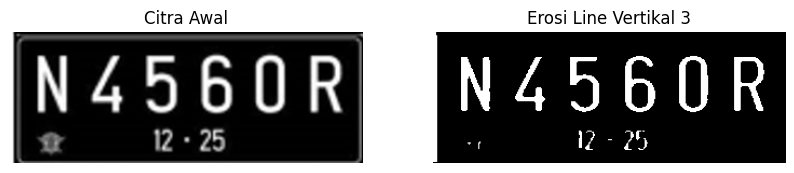

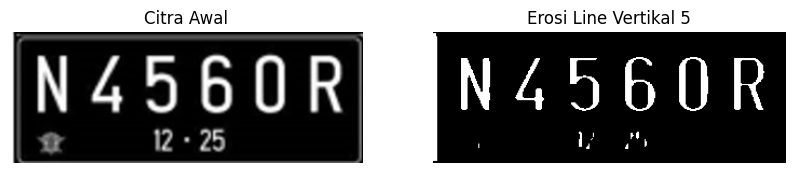

In [25]:
def erosi_vertikal(F, k):
    m, n = F.shape

    SE = np.ones((k, 1), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m-constant):
        for j in range(n):
            temp = F[i-constant:i+constant+1, j:j+1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


img_e = cv2.imread(PLATE_PATH, 0)
ret, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

# Line Vertikal 3
k = 3
imgE = erosi_vertikal(thresh1, k)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(imgE, cmap='gray')
plt.title('Erosi Line Vertikal 3')
plt.axis('off')
plt.show()


# Line Vertikal 5
k = 5
imgE = erosi_vertikal(thresh1, k)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(imgE, cmap='gray')
plt.title('Erosi Line Vertikal 5')
plt.axis('off')
plt.show()

## 13. Transformasi Top Hat

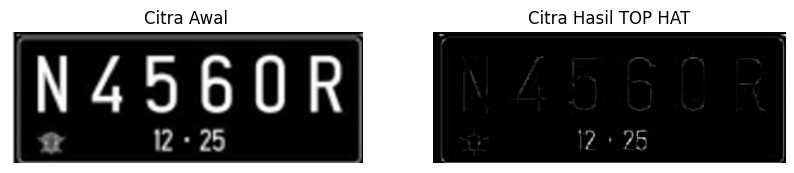

In [26]:
filterSize = (3, 3)

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, filterSize
)

img = cv2.imread(PLATE_PATH, 0)

tophat_img = cv2.morphologyEx(
    img, cv2.MORPH_TOPHAT, kernel
)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT')
plt.axis('off')
plt.show()

## 14. Transformasi Black Hat / Bottom Hat

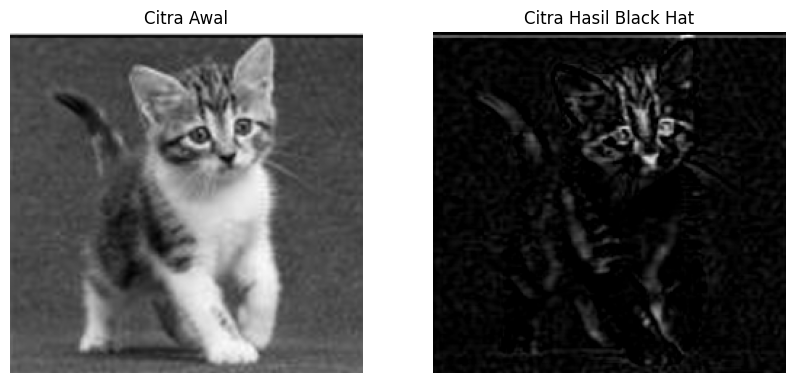

In [27]:
filterSize = (3, 3)

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, filterSize
)

img = cv2.imread(KITTEN_PATH, 0)

Kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (13, 5)
)

blackhat = cv2.morphologyEx(
    img, cv2.MORPH_BLACKHAT, Kernel
)

plt.figure(figsize=(10, 5))
plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.axis('off')

plt.subplot(122)
plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat')
plt.axis('off')
plt.show()

## 15. Skeleton

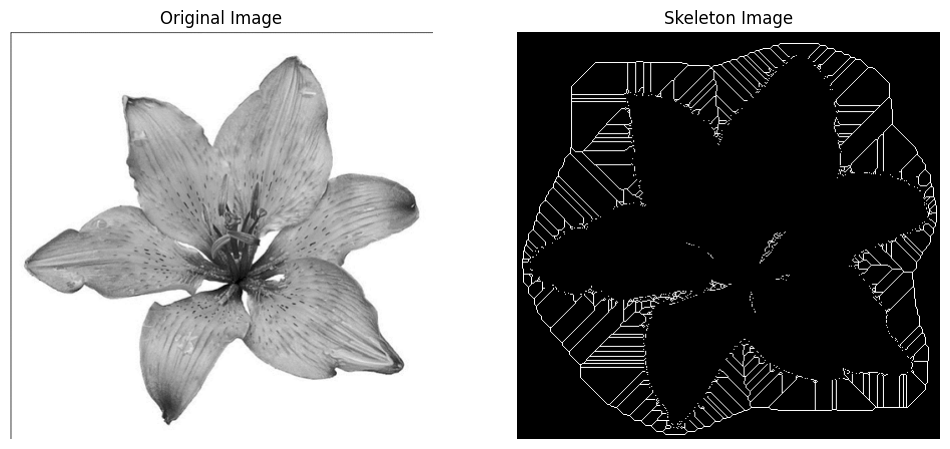

In [28]:
from skimage import filters
from skimage.morphology import skeletonize

img = cv2.imread(LILY_PATH, 0)

binary = img > filters.threshold_triangle(img)

binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

skeleton = skeletonize(binary_cp)

plt.figure(figsize=(12, 8))

plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(122)
plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image')
plt.axis('off')

plt.savefig('binary and bin_skeleton.png')
plt.show()

## 16. Skeleton Inverse

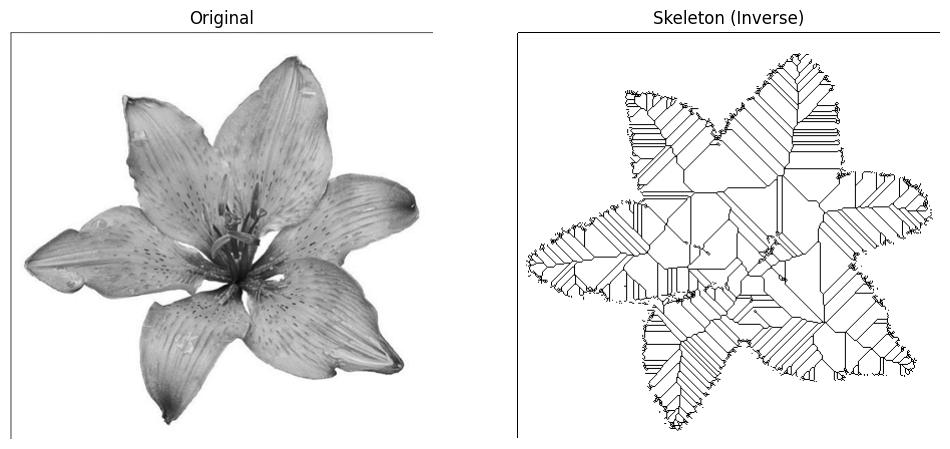

In [29]:
from skimage import io
from skimage import filters
from skimage.morphology import skeletonize
from matplotlib import pyplot as plt

img = io.imread(LILY_PATH)[..., 0]

# Bagian hitam menjadi True
binary = img < filters.threshold_triangle(img)

skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original')
ax[0].set_axis_off()

ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('Skeleton (Inverse)')
ax[1].set_axis_off()

plt.show()

## 17. Thickening (sesuai kode pada modul)


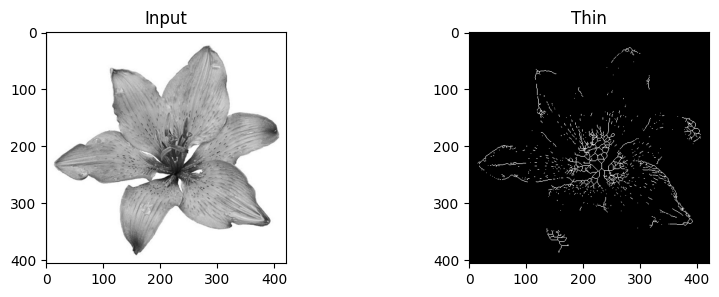

In [31]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

# Membaca gambar Lily
img = io.imread(LILY_PATH)

# Mengubah RGBA menjadi RGB jika memiliki 4 channel
if img.ndim == 3 and img.shape[-1] == 4:
    img = color.rgba2rgb(img)

# Mengubah gambar menjadi grayscale
image = img_as_float(color.rgb2gray(img))

# Membuat citra biner
image_binary = image < 0.5

# Proses skeleton dan thinning
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

# Menampilkan hasil
f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()